In [1]:
!pip install -q shap lime xgboost scikit-learn pandas numpy matplotlib

import os
import time
import math
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
np.random.seed(42)

os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

def extract_sld(domain: str) -> str:
    clean = str(domain).lower().strip()
    parts = clean.split(".")
    if len(parts) >= 3 and parts[-2] in {"co", "com", "org", "net", "gov", "ac", "edu"}:
        return parts[-3]
    return parts[0]

DATASET_URL = "https://raw.githubusercontent.com/chrmor/DGA_domains_dataset/master/dga_domains_full.csv"
raw_df = pd.read_csv(DATASET_URL, header=None, names=["class_str", "family", "domain"]).dropna(subset=["domain"])
raw_df["label"] = (raw_df["class_str"].str.lower() == "dga").astype(int)

benign_df = raw_df[raw_df["label"] == 0].sample(n=10000, random_state=42)
dga_df = raw_df[raw_df["label"] == 1].sample(n=10000, random_state=42)

df = pd.concat([benign_df, dga_df], ignore_index=True)
df = df.sample(frac=1.0, random_state=42).reset_index(drop=True)
df["sld"] = df["domain"].apply(extract_sld)
df = df[df["sld"].str.len() > 1].reset_index(drop=True)

df.head(5000)[["domain", "sld", "family", "label"]].to_csv("data/sample_domains.csv", index=False)

print(f"Total domains: {len(df):,}")
print(df["label"].value_counts().rename({0: "Benign (0)", 1: "DGA (1)"}))
print(df[["domain", "sld", "family", "label"]].head(8).to_string(index=False))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Total domains: 20,000
label
DGA (1)       10000
Benign (0)    10000
Name: count, dtype: int64
                        domain                        sld  family  label
         vqb1rrqev5hoxavfhs.cn         vqb1rrqev5hoxavfhs  rovnix      1
                      cuny.edu                       cuny   alexa      0
          spurscommunity.co.uk             spurscommunity   alexa      0
                  albelady.com                   albelady   alexa      0
          xdjmsdlbxwqbetwgf.tw          xdjmsdlbxwqbetwgf ranbyus      1
            pbraoqwiktcwxd.com             pbraoqwiktcwxd  ramnit      1
spiritreactcommitrulereact.com spiritreactcommitrulereact  matsnu      1
                  xhasters.com                   xhasters   alexa      0


In [2]:
VOWELS = set("aeiou")
CONSONANT_STREAK_RE = re.compile(r"[bcdfghjklmnpqrstvwxyz]+")

def shannon_entropy(s: str) -> float:
    n = len(s)
    if n <= 1:
        return 0.0
    counts = {}
    for ch in s:
        counts[ch] = counts.get(ch, 0) + 1
    return -sum((c / n) * math.log2(c / n) for c in counts.values())

def normalized_entropy(s: str) -> float:
    n = len(s)
    if n <= 1:
        return 0.0
    return shannon_entropy(s) / math.log2(n)

def vowel_ratio(s: str) -> float:
    if not s:
        return 0.0
    return sum(1 for ch in s if ch in VOWELS) / len(s)

def digit_ratio(s: str) -> float:
    if not s:
        return 0.0
    return sum(1 for ch in s if ch.isdigit()) / len(s)

def max_consonant_streak(s: str) -> int:
    streaks = CONSONANT_STREAK_RE.findall(s)
    return max((len(st) for st in streaks), default=0)

t0 = time.perf_counter()
df["sld_length"] = df["sld"].apply(len)
df["shannon_entropy"] = df["sld"].apply(shannon_entropy)
df["norm_entropy"] = df["sld"].apply(normalized_entropy)
df["vowel_ratio"] = df["sld"].apply(vowel_ratio)
df["digit_ratio"] = df["sld"].apply(digit_ratio)
df["max_consonant_streak"] = df["sld"].apply(max_consonant_streak)
lexical_time_ms = (time.perf_counter() - t0) * 1000

LEXICAL_COLS = [
    "sld_length",
    "shannon_entropy",
    "norm_entropy",
    "vowel_ratio",
    "digit_ratio",
    "max_consonant_streak"
]

print(f"Feature extraction completed in {lexical_time_ms:.2f} ms")
print(df.groupby("label")[LEXICAL_COLS].mean().round(4).to_string())

Feature extraction completed in 477.15 ms
       sld_length  shannon_entropy  norm_entropy  vowel_ratio  digit_ratio  max_consonant_streak
label                                                                                           
0         10.6491           2.8416        0.8724       0.3609       0.0207                2.4937
1         14.1494           3.1632        0.8587       0.2749       0.0366                4.7963


In [3]:
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix

train_idx, test_idx = train_test_split(
    df.index, test_size=0.20, random_state=42, stratify=df["label"]
)

df_train = df.loc[train_idx].reset_index(drop=True)
df_test = df.loc[test_idx].reset_index(drop=True)

# Build Markov character-trigram log-likelihood model on training benign domains only
benign_trigrams = Counter()
total_benign_trigrams = 0
for sld in df_train.loc[df_train["label"] == 0, "sld"]:
    padded = f"^{sld}$"
    for i in range(len(padded) - 2):
        benign_trigrams[padded[i:i+3]] += 1
        total_benign_trigrams += 1

vocab_size = max(len(benign_trigrams), 1)

def benign_trigram_log_prob(s: str) -> float:
    padded = f"^{s}$"
    k = max(len(padded) - 2, 1)
    log_sum = 0.0
    for i in range(len(padded) - 2):
        tg = padded[i:i+3]
        prob = (benign_trigrams.get(tg, 0) + 1.0) / (total_benign_trigrams + vocab_size)
        log_sum += math.log2(prob)
    return log_sum / k

df_train["trigram_ll"] = df_train["sld"].apply(benign_trigram_log_prob)
df_test["trigram_ll"] = df_test["sld"].apply(benign_trigram_log_prob)

ALL_LEX_COLS = LEXICAL_COLS + ["trigram_ll"]

y_train = df_train["label"].values
y_test = df_test["label"].values

X_train_lex = df_train[ALL_LEX_COLS].values
X_test_lex = df_test[ALL_LEX_COLS].values

vectorizer = TfidfVectorizer(analyzer="char", ngram_range=(3, 4), max_features=300, sublinear_tf=True)
X_train_ng = vectorizer.fit_transform(df_train["sld"])
X_test_ng = vectorizer.transform(df_test["sld"])

X_train_hybrid = hstack([csr_matrix(X_train_lex), X_train_ng]).tocsr()
X_test_hybrid = hstack([csr_matrix(X_test_lex), X_test_ng]).tocsr()

ngram_names = [f"ng_{g}" for g in vectorizer.get_feature_names_out()]
HYBRID_FEATURE_NAMES = ALL_LEX_COLS + ngram_names

print(f"Train samples: {X_train_hybrid.shape[0]:,} | Test samples: {X_test_hybrid.shape[0]:,}")
print(f"Dense feature matrix: {X_train_lex.shape} | Hybrid sparse matrix: {X_train_hybrid.shape}")

Train samples: 16,000 | Test samples: 4,000
Dense feature matrix: (16000, 7) | Hybrid sparse matrix: (16000, 307)


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
)

# Tune XGBoost hyperparameters via 3-fold RandomizedSearchCV on the training split
param_dist = {
    "max_depth": [6, 8, 10],
    "learning_rate": [0.05, 0.1, 0.15],
    "n_estimators": [150, 250],
    "colsample_bytree": [0.5, 0.7, 1.0],
    "subsample": [0.8, 1.0]
}

xgb_search = RandomizedSearchCV(
    XGBClassifier(random_state=42, eval_metric="logloss"),
    param_distributions=param_dist,
    n_iter=6,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=-1
)
xgb_search.fit(X_train_lex, y_train)
best_params = xgb_search.best_params_
print(f"Selected XGBoost parameters (3-fold CV): {best_params}\n")

experiments = [
    ("Logistic Regression (7 Dense Feats)", LogisticRegression(max_iter=500), X_train_lex, X_test_lex),
    ("Random Forest (7 Dense Feats)", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1), X_train_lex, X_test_lex),
    ("XGBoost (7 Dense Feats)", XGBClassifier(**best_params, random_state=42, eval_metric="logloss"), X_train_lex, X_test_lex),
    ("Random Forest (Hybrid: Dense + TF-IDF)", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1), X_train_hybrid, X_test_hybrid),
    ("XGBoost (Hybrid: Dense + TF-IDF)", XGBClassifier(**best_params, random_state=42, eval_metric="logloss"), X_train_hybrid, X_test_hybrid),
]

results_rows = []
trained_models = {}

for name, model, X_tr, X_te in experiments:
    model.fit(X_tr, y_train)

    t_inf = time.perf_counter()
    y_pred = model.predict(X_te)
    inf_ms_per_1k = ((time.perf_counter() - t_inf) * 1000) / (X_te.shape[0] / 1000.0)

    y_prob = model.predict_proba(X_te)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    results_rows.append({
        "Configuration": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1_Score": round(f1_score(y_test, y_pred), 4),
        "ROC_AUC": round(roc_auc_score(y_test, y_prob), 4),
        "FPR": round(fp / (fp + tn), 4),
        "Latency_ms_per_1k": round(inf_ms_per_1k, 3)
    })
    trained_models[name] = (model, y_pred)

results_df = pd.DataFrame(results_rows)
print(results_df.to_string(index=False))

xgb_lex_model, xgb_lex_pred = trained_models["XGBoost (7 Dense Feats)"]
xgb_hyb_model, xgb_hyb_pred = trained_models["XGBoost (Hybrid: Dense + TF-IDF)"]

print("\nConfusion Matrix - XGBoost Hybrid:")
print(confusion_matrix(y_test, xgb_hyb_pred))

Selected XGBoost parameters (3-fold CV): {'subsample': 0.8, 'n_estimators': 150, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.5}

                         Configuration  Accuracy  Precision  Recall  F1_Score  ROC_AUC    FPR  Latency_ms_per_1k
   Logistic Regression (7 Dense Feats)    0.8452     0.8557  0.8305    0.8429   0.9133 0.1400              0.138
         Random Forest (7 Dense Feats)    0.8568     0.8635  0.8475    0.8554   0.9264 0.1340            139.892
               XGBoost (7 Dense Feats)    0.8670     0.9007  0.8250    0.8612   0.9334 0.0910             11.980
Random Forest (Hybrid: Dense + TF-IDF)    0.8775     0.9085  0.8395    0.8727   0.9364 0.0845             50.427
      XGBoost (Hybrid: Dense + TF-IDF)    0.8725     0.9036  0.8340    0.8674   0.9383 0.0890              6.346

Confusion Matrix - XGBoost Hybrid:
[[1822  178]
 [ 332 1668]]


### Model explainability using TreeSHAP

Using TreeSHAP to explain the predictions made by our model using a sample of 500 test instances, shown through a global Beeswarm plot and a local waterfall plot.

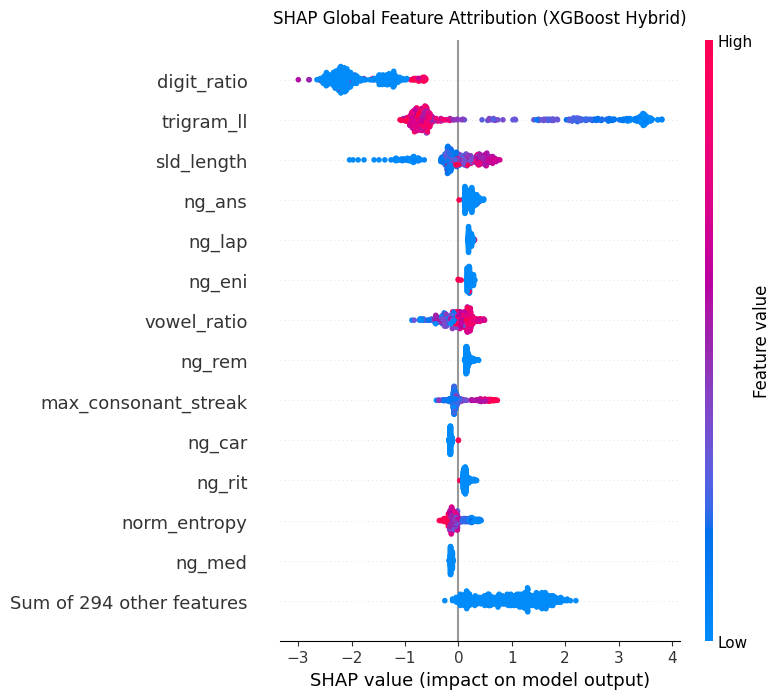

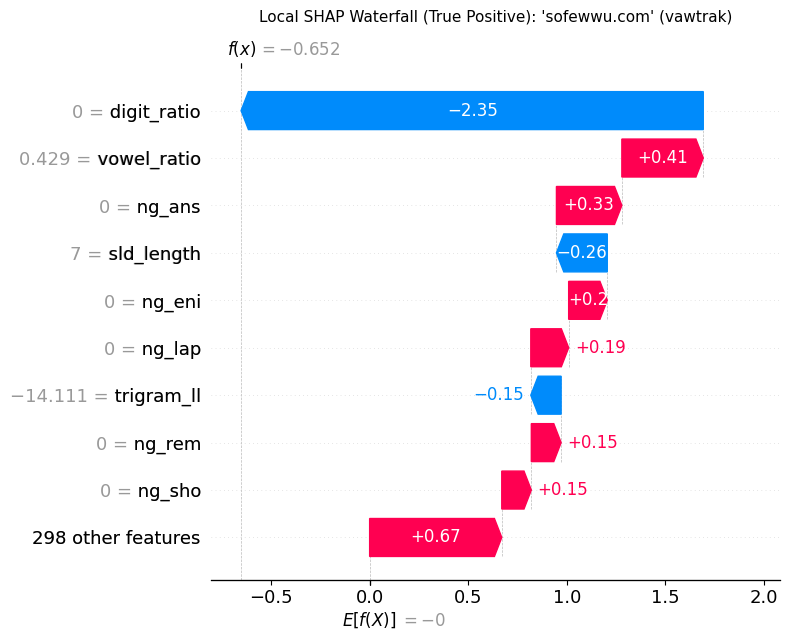

In [5]:
import shap

sample_size = 500
X_shap_sample = pd.DataFrame(
    X_test_hybrid[:sample_size].toarray(),
    columns=HYBRID_FEATURE_NAMES
)

explainer_xgb = shap.TreeExplainer(xgb_hyb_model)
shap_values = explainer_xgb(X_shap_sample)

plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values, max_display=14, show=False)
plt.title("SHAP Global Feature Attribution (XGBoost Hybrid)", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("figures/shap_global_beeswarm.png", dpi=300, bbox_inches="tight")
plt.show()

# Filter specifically for a True Positive DGA detection (y_true == 1 and y_pred == 1)
tp_indices = np.where((y_test[:sample_size] == 1) & (xgb_hyb_pred[:sample_size] == 1))[0]
target_idx = tp_indices[0]
target_domain_name = df_test.loc[target_idx, "domain"]
target_family = df_test.loc[target_idx, "family"]

plt.figure(figsize=(9, 5))
shap.plots.waterfall(shap_values[target_idx], max_display=10, show=False)
plt.title(f"Local SHAP Waterfall (True Positive): '{target_domain_name}' ({target_family})", fontsize=11, pad=12)
plt.tight_layout()
plt.savefig("figures/shap_local_waterfall.png", dpi=300, bbox_inches="tight")
plt.show()

### XAI stability and Edge case stress testing

Comparing TreeSHAP and LIME explanations to figure out better performer in terms of ranking consistency and average query time. Stress tested 6 specific domains against edge cases and final results displayed.

In [6]:
from lime.lime_tabular import LimeTabularExplainer

lex_explainer_shap = shap.TreeExplainer(xgb_lex_model)
target_row = X_test_lex[target_idx : target_idx + 1]

shap_top3_runs = []
t0 = time.perf_counter()
for _ in range(5):
    sv = lex_explainer_shap.shap_values(target_row)[0]
    top3 = tuple(np.argsort(np.abs(sv))[::-1][:3])
    shap_top3_runs.append(top3)
shap_ms = ((time.perf_counter() - t0) * 1000) / 5.0

lime_top3_runs = []
t0 = time.perf_counter()
for seed in range(1, 6):
    lime_exp = LimeTabularExplainer(
        X_train_lex,
        feature_names=ALL_LEX_COLS,
        class_names=["Benign", "DGA"],
        mode="classification",
        random_state=seed
    )
    exp = lime_exp.explain_instance(target_row[0], xgb_lex_model.predict_proba, num_features=7, num_samples=500)
    ranked_feats = tuple(idx for idx, _ in exp.local_exp[1][:3])
    lime_top3_runs.append(ranked_feats)
lime_ms = ((time.perf_counter() - t0) * 1000) / 5.0

print(f"Evaluated domain: {target_domain_name} ({target_family})")
print(f"TreeSHAP -> {shap_ms:.3f} ms/query | Unique top-3 feature rankings across 5 runs: {len(set(shap_top3_runs))}")
print(f"LIME     -> {lime_ms:.3f} ms/query | Unique top-3 feature rankings across 5 runs: {len(set(lime_top3_runs))}")

edge_cases = [
    ("google.com", "Standard Benign"),
    ("car.com", "Short Benign (Max Normalized Entropy)"),
    ("gym.com", "Short Benign (No Standard Vowels)"),
    ("xkqz994j18a.info", "Alphanumeric PRNG DGA"),
    ("qzdfhgjklmnp.ru", "Consonant-Cluster DGA"),
    ("greenapplechair.com", "Wordlist Concatenation DGA")
]

stress_rows = []
for dom, category in edge_cases:
    sld = extract_sld(dom)
    feats = np.array([[
        len(sld),
        shannon_entropy(sld),
        normalized_entropy(sld),
        vowel_ratio(sld),
        digit_ratio(sld),
        max_consonant_streak(sld),
        benign_trigram_log_prob(sld)
    ]])
    ng = vectorizer.transform([sld])
    hyb_input = hstack([csr_matrix(feats), ng]).tocsr()
    prob_dga = xgb_hyb_model.predict_proba(hyb_input)[0, 1]
    stress_rows.append({
        "Domain": dom,
        "Category": category,
        "Raw_H": round(feats[0, 1], 2),
        "Norm_H": round(feats[0, 2], 2),
        "Trigram_LL": round(feats[0, 6], 2),
        "DGA_Prob": round(float(prob_dga), 4),
        "Verdict": "BLOCK (1)" if prob_dga >= 0.5 else "ALLOW (0)"
    })

print("\nEdge-Case Diagnostic Results:")
print(pd.DataFrame(stress_rows).to_string(index=False))

Evaluated domain: sofewwu.com (vawtrak)
TreeSHAP -> 3.607 ms/query | Unique top-3 feature rankings across 5 runs: 1
LIME     -> 57.712 ms/query | Unique top-3 feature rankings across 5 runs: 3

Edge-Case Diagnostic Results:
             Domain                              Category  Raw_H  Norm_H  Trigram_LL  DGA_Prob   Verdict
         google.com                       Standard Benign   1.92    0.74      -12.34    0.0629 ALLOW (0)
            car.com Short Benign (Max Normalized Entropy)   1.58    1.00      -10.07    0.0120 ALLOW (0)
            gym.com     Short Benign (No Standard Vowels)   1.58    1.00      -14.92    0.0166 ALLOW (0)
   xkqz994j18a.info                 Alphanumeric PRNG DGA   3.28    0.95      -16.56    0.9803 BLOCK (1)
    qzdfhgjklmnp.ru                 Consonant-Cluster DGA   3.58    1.00      -16.31    0.9963 BLOCK (1)
greenapplechair.com            Wordlist Concatenation DGA   3.19    0.82      -11.32    0.2395 ALLOW (0)
